Using file: /content/retail_store_sales.csv
(12575, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  object 
 1   Customer ID       12575 non-null  object 
 2   Category          12575 non-null  object 
 3   Item              11362 non-null  object 
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  object 
 8   Location          12575 non-null  object 
 9   Transaction Date  12575 non-null  object 
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(8)
memory usage: 1.1+ MB
transaction_id         0
customer_id            0
category               0
item                1213
price_per_unit       609
quantity             604
total_spent          6

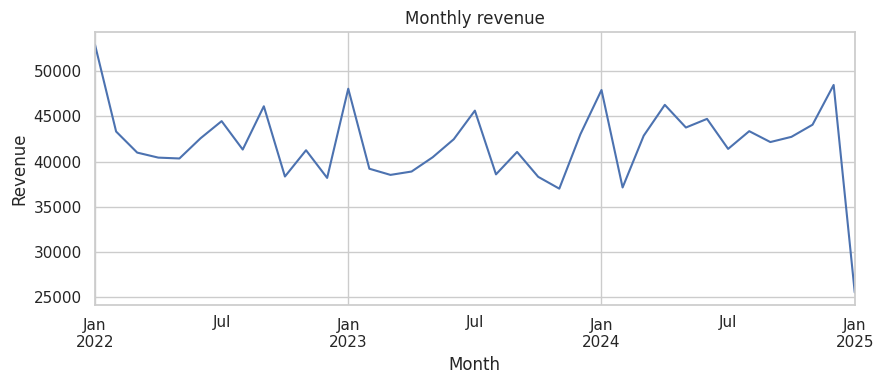

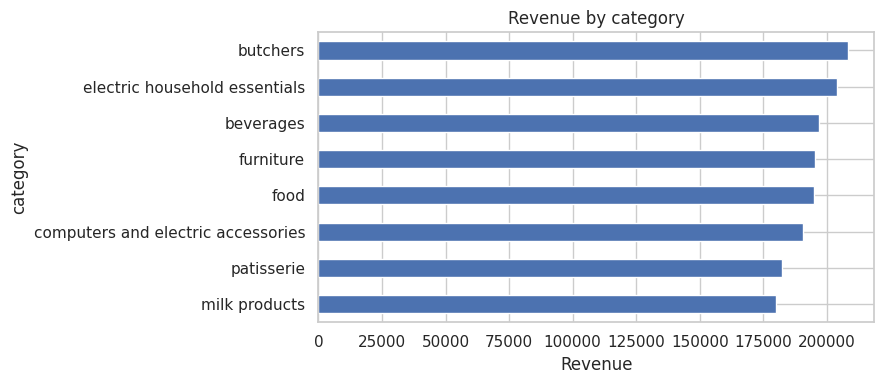

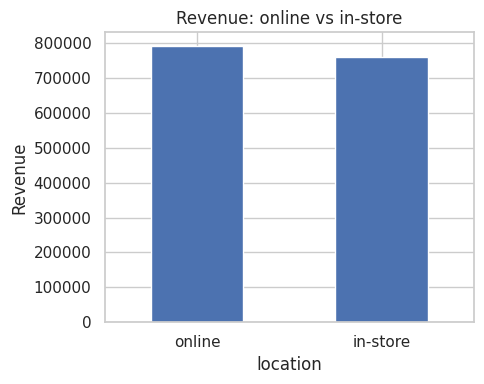

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ===== 1. LOAD AND INSPECT =====
import glob, os
candidates = (glob.glob("/content/*retail*.csv") + glob.glob("/content/*sales*.csv")
              + glob.glob("*retail*.csv") + glob.glob("*sales*.csv"))
if candidates:
    path = candidates[0]
else:
    from google.colab import files
    print("Dataset not found. Please upload your retail sales CSV.")
    path = list(files.upload().keys())[0]
print("Using file:", path)
df = pd.read_csv(path)

print(df.shape)
df.info()
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# ===== 2. CLEAN =====
print(df.isnull().sum())

# text columns first (payment_method uses its OWN column)
for col in ["category", "payment_method", "location"]:
    df[col] = df[col].astype(str).str.strip().str.lower()
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

# categorical gaps: label them instead of guessing
df["item"] = df["item"].fillna("unknown")
df["discount_applied"] = df["discount_applied"].fillna("unknown").astype(str).str.lower()

# numeric gaps: rebuild from the other two columns (total = price x quantity)
df["price_per_unit"] = df["price_per_unit"].fillna(df["total_spent"] / df["quantity"])
df["quantity"] = df["quantity"].fillna(df["total_spent"] / df["price_per_unit"])
df["total_spent"] = df["total_spent"].fillna(df["price_per_unit"] * df["quantity"])
before = len(df)
df = df.dropna(subset=["price_per_unit", "quantity", "total_spent"])
print("Rows dropped (2+ numeric values missing):", before - len(df))

print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# outliers: count them, but keep them (high totals are valid big orders)
Q1, Q3 = df["total_spent"].quantile([0.25, 0.75])
IQR = Q3 - Q1
outside = ((df["total_spent"] < Q1 - 1.5 * IQR) | (df["total_spent"] > Q3 + 1.5 * IQR)).sum()
print("Rows outside IQR fences (kept):", outside)
print("Final shape:", df.shape, "| nulls left:", int(df.isnull().sum().sum()))

# ===== 3. ANALYSIS =====
total_revenue = df["total_spent"].sum()
print("\nTotal revenue:", round(total_revenue, 2))
print("Date range:", df["transaction_date"].min().date(), "to", df["transaction_date"].max().date())

category_sales = df.groupby("category")["total_spent"].sum().sort_values(ascending=False)
print("\nRevenue by category:\n", category_sales)
print("\nShare by category (%):\n", (category_sales / total_revenue * 100).round(1))

payment_sales = df.groupby("payment_method")["total_spent"].sum().sort_values(ascending=False)
print("\nRevenue by payment method:\n", payment_sales)

location_sales = df.groupby("location")["total_spent"].sum().sort_values(ascending=False)
print("\nRevenue by location:\n", location_sales)

# month of year, and each calendar month separately (avoids mixing years)
df["month"] = df["transaction_date"].dt.month
month_of_year = df.groupby("month")["total_spent"].sum()
print("\nRevenue by month of year:\n", month_of_year)
monthly = df.groupby(df["transaction_date"].dt.to_period("M"))["total_spent"].sum()
print("\nNumber of months in data:", len(monthly))

# items: exclude the 'unknown' placeholder
item_sales = df[df["item"] != "unknown"].groupby("item")["total_spent"].sum().sort_values(ascending=False)
print("\nTop 10 items:\n", item_sales.head(10))

# ===== 4. CHARTS =====
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax)
ax.set_title("Monthly revenue")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue")
plt.tight_layout(); plt.savefig("monthly_revenue.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
category_sales.sort_values().plot.barh(ax=ax)
ax.set_title("Revenue by category"); ax.set_xlabel("Revenue")
plt.tight_layout(); plt.savefig("category_revenue.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
location_sales.plot.bar(ax=ax, rot=0)
ax.set_title("Revenue: online vs in-store"); ax.set_ylabel("Revenue")
plt.tight_layout(); plt.savefig("location_revenue.png", dpi=150); plt.show()